In [1]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

GPU 0: Tesla T4 (UUID: GPU-e852edc2-4038-f3f5-a5bd-ed0aad2db4c2)
Mounted at /content/drive


In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
assert os.path.exists('/content/drive/MyDrive'), 'Drive chưa mount, chạy lại cell mount'

# Tìm folder violence_project trong lab_ATvsBMTT (đã chuyển vào "đồ án môn")
found = [p for p in Path('/content/drive/MyDrive/lab_ATvsBMTT').rglob('violence_project') if p.is_dir()]
assert found, 'Không thấy folder violence_project. Kiểm tra lại tên folder trên Drive.'
OUT_DIR = found[0]
print('OUT_DIR =', OUT_DIR)

CK  = OUT_DIR / 'checkpoints' / 'best.pt'
SPL = OUT_DIR / 'splits'
THR = 0.61            # ngưỡng chọn trên tập val

for p in [CK, SPL/'rlvs_test.csv', SPL/'hockey_all.csv', OUT_DIR/'pred_hockey.csv']:
    print('OK   ' if p.exists() else 'THIẾU', p)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

OUT_DIR = /content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/violence_project
OK    /content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/violence_project/checkpoints/best.pt
OK    /content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/violence_project/splits/rlvs_test.csv
OK    /content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/violence_project/splits/hockey_all.csv
OK    /content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/violence_project/pred_hockey.csv


In [3]:
cfg = {
 'Mô hình nền': 'VideoMAE-base, pretrained trên Kinetics-400 (MCG-NJU/videomae-base-finetuned-kinetics)',
 'Bài toán': 'Phân loại clip 2 lớp: đánh nhau / không đánh nhau',
 'Dữ liệu train': 'Real Life Violence Dataset (RLVS): 1407 train / 302 val / 302 test (70/15/15, phân tầng theo nhãn, seed 42)',
 'Dữ liệu test chéo': 'Hockey Fights: 1000 clip (500 / 500), không dùng để train hay chọn tham số',
 'Đầu vào': '16 frame lấy đều mỗi clip, resize 256 rồi crop 224, chuẩn hóa theo ImageNet',
 'Augmentation (train)': 'Lấy frame ngẫu nhiên trong từng đoạn, crop ngẫu nhiên, lật ngang',
 'Tối ưu': 'AdamW, weight decay 0.05, lr thân 2e-5 / lr lớp cuối 2e-4, warmup 10% rồi giảm cosine',
 'Batch': '4 x 4 (tích lũy gradient) = 16 hiệu dụng',
 'Số epoch': '5 (checkpoint tốt nhất theo val F1: epoch 4)',
 'Độ chính xác số': 'Mixed precision fp16, GradScaler, cắt gradient 1.0',
 'Phần cứng': 'Google Colab GPU T4, khoảng 28 phút mỗi epoch',
 'Ngưỡng cảnh báo': f'{THR} (chọn trên tập val, không nhìn Hockey)',
}
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(cfg.items(), columns=['Thông số', 'Giá trị']).style.hide(axis='index'))

Thông số,Giá trị
Mô hình nền,"VideoMAE-base, pretrained trên Kinetics-400 (MCG-NJU/videomae-base-finetuned-kinetics)"
Bài toán,Phân loại clip 2 lớp: đánh nhau / không đánh nhau
Dữ liệu train,"Real Life Violence Dataset (RLVS): 1407 train / 302 val / 302 test (70/15/15, phân tầng theo nhãn, seed 42)"
Dữ liệu test chéo,"Hockey Fights: 1000 clip (500 / 500), không dùng để train hay chọn tham số"
Đầu vào,"16 frame lấy đều mỗi clip, resize 256 rồi crop 224, chuẩn hóa theo ImageNet"
Augmentation (train),"Lấy frame ngẫu nhiên trong từng đoạn, crop ngẫu nhiên, lật ngang"
Tối ưu,"AdamW, weight decay 0.05, lr thân 2e-5 / lr lớp cuối 2e-4, warmup 10% rồi giảm cosine"
Batch,4 x 4 (tích lũy gradient) = 16 hiệu dụng
Số epoch,5 (checkpoint tốt nhất theo val F1: epoch 4)
Độ chính xác số,"Mixed precision fp16, GradScaler, cắt gradient 1.0"


epoch,train_loss,val_acc,val_precision,val_recall,val_f1,phut
1,0.2742,0.9735,0.9931,0.9533,0.9728,28.9000
2,0.0415,0.9868,0.9803,0.9933,0.9868,28.2000
3,0.0133,0.9868,0.9867,0.9867,0.9867,28.2000
4,0.0058,0.9934,0.9868,1.0000,0.9934,28.5000
5,0.0033,0.9934,0.9933,0.9933,0.9933,28.8000


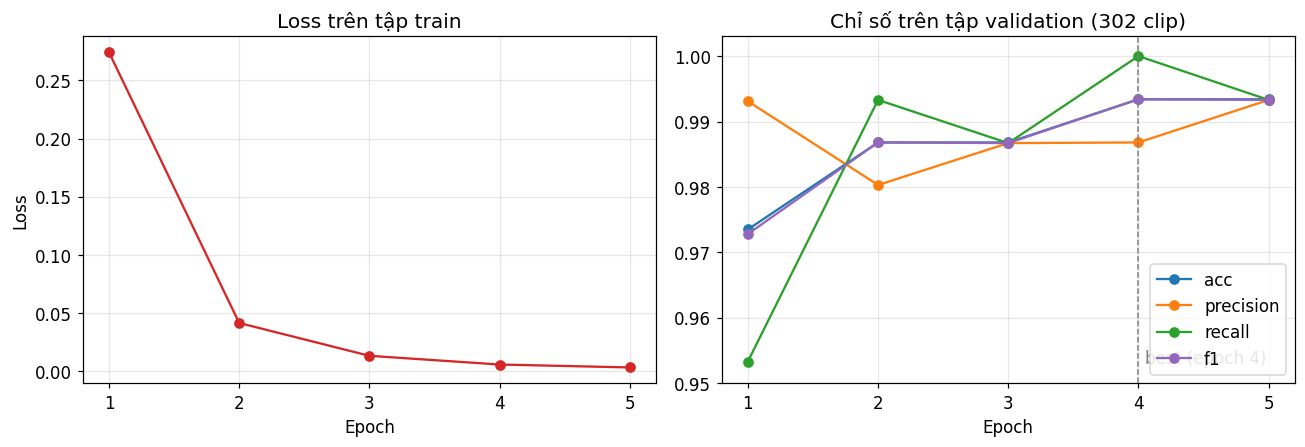

In [4]:
hist = pd.DataFrame({
 'epoch':         [1, 2, 3, 4, 5],
 'train_loss':    [0.2742, 0.0415, 0.0133, 0.0058, 0.0033],
 'val_acc':       [0.9735, 0.9868, 0.9868, 0.9934, 0.9934],
 'val_precision': [0.9931, 0.9803, 0.9867, 0.9868, 0.9933],
 'val_recall':    [0.9533, 0.9933, 0.9867, 1.0,    0.9933],
 'val_f1':        [0.9728, 0.9868, 0.9867, 0.9934, 0.9933],
 'phut':          [28.9, 28.2, 28.2, 28.5, 28.8],
})
display(hist.style.hide(axis='index').format(precision=4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(hist.epoch, hist.train_loss, 'o-', color='tab:red')
ax[0].set_title('Loss trên tập train'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].set_xticks(hist.epoch); ax[0].grid(alpha=.3)
for m, c in [('val_acc','tab:blue'), ('val_precision','tab:orange'), ('val_recall','tab:green'), ('val_f1','tab:purple')]:
    ax[1].plot(hist.epoch, hist[m], 'o-', label=m.replace('val_',''), color=c)
ax[1].axvline(4, color='gray', ls='--', lw=1); ax[1].text(4.05, 0.953, 'best (epoch 4)', color='gray')
ax[1].set_ylim(0.95, 1.003); ax[1].set_xticks(hist.epoch); ax[1].set_title('Chỉ số trên tập validation (302 clip)')
ax[1].set_xlabel('Epoch'); ax[1].legend(loc='lower right'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

Hockey: tính lại từ pred_hockey.csv


Bộ test,Số clip,Accuracy,Precision,Recall,F1
RLVS test (cùng miền với train),302,99.34%,98.68%,100.00%,99.34%
"Hockey (test chéo, khác miền)",1000,80.90%,74.10%,95.00%,83.26%


AUC trên Hockey: 0.934   |   ngưỡng cảnh báo = 0.61


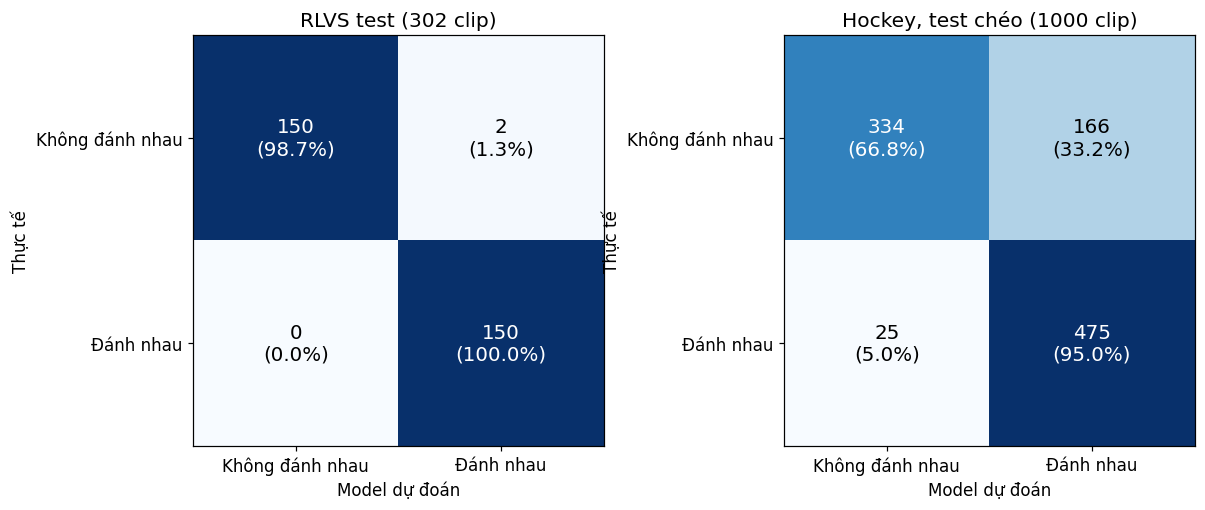

In [5]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

hp = OUT_DIR / 'pred_hockey.csv'
if hp.exists():
    hk = pd.read_csv(hp)
    cm_h = confusion_matrix(hk.label, (hk.prob >= THR).astype(int))
    auc_h = roc_auc_score(hk.label, hk.prob)
    print('Hockey: tính lại từ pred_hockey.csv')
else:
    hk, cm_h, auc_h = None, np.array([[334, 166], [25, 475]]), 0.934
    print('Hockey: dùng số liệu đã ghi lại (không thấy pred_hockey.csv)')
cm_r = np.array([[150, 2], [0, 150]])          # RLVS test, ghi từ lần đánh giá

def prf(cm):
    tn, fp, fn, tp = cm.ravel()
    pr, rc = tp / (tp + fp), tp / (tp + fn)
    return (tp + tn) / cm.sum(), pr, rc, 2 * pr * rc / (pr + rc)

rows = []
for name, cm in [('RLVS test (cùng miền với train)', cm_r), ('Hockey (test chéo, khác miền)', cm_h)]:
    a, p, r, f = prf(cm); rows.append([name, int(cm.sum()), a, p, r, f])
res = pd.DataFrame(rows, columns=['Bộ test', 'Số clip', 'Accuracy', 'Precision', 'Recall', 'F1'])
display(res.style.hide(axis='index').format({c: '{:.2%}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']}))
print(f'AUC trên Hockey: {auc_h:.3f}   |   ngưỡng cảnh báo = {THR}')

def plot_cm(ax, cm, title):
    names = ['Không đánh nhau', 'Đánh nhau']
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_xticklabels(names); ax.set_yticks([0, 1]); ax.set_yticklabels(names)
    ax.set_xlabel('Model dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})', ha='center', va='center',
                    fontsize=13, color='white' if cm[i, j] > cm.max() / 2 else 'black')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
plot_cm(ax[0], cm_r, 'RLVS test (302 clip)')
plot_cm(ax[1], cm_h, 'Hockey, test chéo (1000 clip)')
plt.tight_layout(); plt.show()

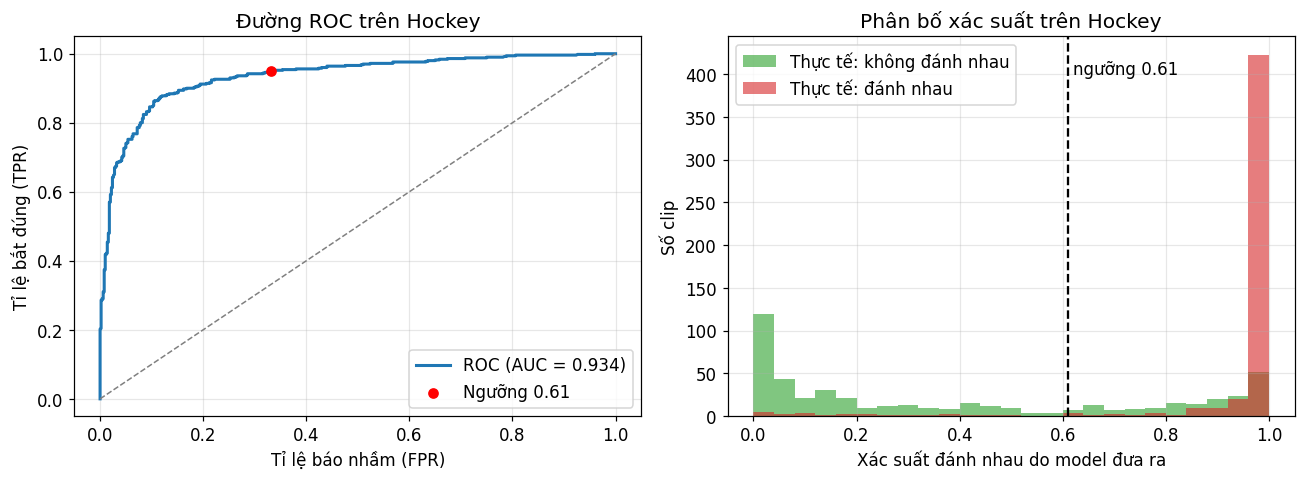

In [6]:
if hk is None:
    print('Chưa có pred_hockey.csv, bỏ qua biểu đồ này.')
else:
    fpr, tpr, _ = roc_curve(hk.label, hk.prob)
    tn, fp, fn, tp = cm_h.ravel()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].plot(fpr, tpr, lw=2, label=f'ROC (AUC = {auc_h:.3f})')
    ax[0].plot([0, 1], [0, 1], '--', color='gray', lw=1)
    ax[0].scatter([fp / (fp + tn)], [tp / (tp + fn)], color='red', zorder=5, label=f'Ngưỡng {THR}')
    ax[0].set_xlabel('Tỉ lệ báo nhầm (FPR)'); ax[0].set_ylabel('Tỉ lệ bắt đúng (TPR)')
    ax[0].set_title('Đường ROC trên Hockey'); ax[0].legend(loc='lower right'); ax[0].grid(alpha=.3)

    bins = np.linspace(0, 1, 26)
    ax[1].hist(hk[hk.label == 0].prob, bins=bins, alpha=.6, label='Thực tế: không đánh nhau', color='tab:green')
    ax[1].hist(hk[hk.label == 1].prob, bins=bins, alpha=.6, label='Thực tế: đánh nhau', color='tab:red')
    ax[1].axvline(THR, color='k', ls='--'); ax[1].text(THR + .01, ax[1].get_ylim()[1] * .9, f'ngưỡng {THR}')
    ax[1].set_xlabel('Xác suất đánh nhau do model đưa ra'); ax[1].set_ylabel('Số clip')
    ax[1].set_title('Phân bố xác suất trên Hockey'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

DEMO CHO THẦY

In [7]:
!pip install -q transformers
import torch, cv2, time, base64, subprocess, random, zipfile
from IPython.display import HTML, display
from transformers import VideoMAEForVideoClassification

device = 'cuda'
CKPT = 'MCG-NJU/videomae-base-finetuned-kinetics'
model = VideoMAEForVideoClassification.from_pretrained(CKPT, num_labels=2, ignore_mismatched_sizes=True)
model.load_state_dict(torch.load(CK, map_location='cpu'))
model.to(device).eval()
print('Số tham số:', round(sum(p.numel() for p in model.parameters()) / 1e6, 1), 'M | đã nạp', CK.name)

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400, 768]) vs model:torch.Size([2, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400]) vs model:torch.Size([2])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Số tham số: 86.2 M | đã nạp best.pt


In [8]:
NUM_FRAMES, SIZE, CROP = 16, 256, 224
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
MAX_SEC, SEG_SEC, STRIDE_SEC = 60, 3.0, 1.0     # chỉ xử lý tối đa 60 giây đầu; cửa sổ trượt 3 giây, bước 1 giây
DEMO = Path('/content/demo_samples'); DEMO.mkdir(exist_ok=True)

def load_small_frames(path, max_sec=MAX_SEC):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps < 1: fps = 25.0
    frames = []
    while len(frames) < int(max_sec * fps):
        ok, f = cap.read()
        if not ok: break
        frames.append(cv2.resize(f, (SIZE, SIZE)))        # BGR, giống lúc train
    cap.release()
    return (np.stack(frames) if frames else None), fps

def make_input(frames, start, length):
    idx = [min(start + int((k + 0.5) * length / NUM_FRAMES), len(frames) - 1) for k in range(NUM_FRAMES)]
    x = frames[idx][..., ::-1]                              # BGR -> RGB
    o = (SIZE - CROP) // 2
    x = x[:, o:o + CROP, o:o + CROP]                        # crop giữa, như lúc đánh giá
    x = (x.astype(np.float32) / 255 - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2)

@torch.no_grad()
def probs_for(inputs, bs=4):
    out = []
    for i in range(0, len(inputs), bs):
        b = torch.stack(inputs[i:i + bs]).to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            lg = model(pixel_values=b).logits
        out += torch.softmax(lg.float(), -1)[:, 1].cpu().tolist()
    return out

def analyze(frames, fps):
    n = len(frames)
    clip_p = probs_for([make_input(frames, 0, n)])[0]       # cả clip, đúng cách đã train/đánh giá
    win = int(SEG_SEC * fps); stride = max(1, int(STRIDE_SEC * fps))
    if n <= win:
        starts, win = [0], n
    else:
        starts = list(range(0, n - win + 1, stride))
        if starts[-1] + win < n: starts.append(n - win)
    wp = probs_for([make_input(frames, s, win) for s in starts])
    tot, cnt = np.zeros(n), np.zeros(n)
    for s, p in zip(starts, wp):
        tot[s:s + win] += p; cnt[s:s + win] += 1
    return clip_p, tot / np.maximum(cnt, 1)

def write_annotated(path, frame_p, fps, out_path='/content/annotated.mp4'):
    cap = cv2.VideoCapture(str(path)); ok, f = cap.read()
    W = 480; H = int(f.shape[0] * W / f.shape[1]) // 2 * 2
    tmp = '/content/_tmp.mp4'
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H)); i = 0
    while ok and i < len(frame_p):
        f = cv2.resize(f, (W, H)); p = frame_p[i]; fight = p >= THR
        col = (0, 0, 255) if fight else (0, 170, 0)
        cv2.rectangle(f, (0, 0), (W - 1, H - 1), col, 6 if fight else 2)
        cv2.rectangle(f, (0, 0), (W, 34), (0, 0, 0), -1)
        cv2.putText(f, ('FIGHT' if fight else 'NORMAL') + f'  p={p:.2f}', (8, 24),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (60, 60, 255) if fight else (80, 220, 80), 2)
        vw.write(f); ok, f = cap.read(); i += 1
    vw.release(); cap.release()
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', tmp, '-c:v', 'libx264',
                    '-pix_fmt', 'yuv420p', '-movflags', '+faststart', out_path])
    return out_path

def show_video(p):
    b64 = base64.b64encode(open(p, 'rb').read()).decode()
    display(HTML(f'<video width="480" controls loop><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

def demo(path, expected=None):
    t0 = time.time()
    frames, fps = load_small_frames(path)
    if frames is None:
        print('Không đọc được video:', path); return
    clip_p, frame_p = analyze(frames, fps)
    verdict = 'ĐÁNH NHAU' if clip_p >= THR else 'BÌNH THƯỜNG'
    print(f'=== {Path(path).name} | thực tế: {expected or "không rõ"} | model (cả clip): {verdict} (p={clip_p:.2f}) | {time.time() - t0:.1f}s')
    t = np.arange(len(frame_p)) / fps
    fig, ax = plt.subplots(figsize=(9, 2.4))
    ax.plot(t, frame_p, color='tab:blue'); ax.axhline(THR, color='k', ls='--', lw=1)
    ax.fill_between(t, 0, 1, where=frame_p >= THR, color='red', alpha=.15)
    ax.set_ylim(0, 1); ax.set_xlabel('Thời gian (giây)'); ax.set_ylabel('P(đánh nhau)')
    ax.set_title('Xác suất theo cửa sổ trượt 3 giây (vùng đỏ = vượt ngưỡng)'); plt.tight_layout(); plt.show()
    show_video(write_annotated(path, frame_p, fps))

_zip_index = None
def get_clip(rel):
    # lấy đúng 1 file từ zip trên Drive, không cần giải nén cả 2 GB
    global _zip_index
    if _zip_index is None:
        _zip_index = {}
        for z in sorted(Path('/content/drive/MyDrive/lab_ATvsBMTT').rglob('dataset-*.zip')):
            with zipfile.ZipFile(z) as zf:
                for n in zf.namelist(): _zip_index[n] = z
    z = _zip_index.get(rel)
    if z is None: return None
    with zipfile.ZipFile(z) as zf: return zf.extract(rel, DEMO)
print('Sẵn sàng demo.')

Sẵn sàng demo.


In [ ]:
from google.colab import files
up = files.upload()
for name in up:
    demo(name)

In [9]:
rt = pd.read_csv(SPL / 'rlvs_test.csv'); ha = pd.read_csv(SPL / 'hockey_all.csv')
pick = lambda df, lab, k: df[df.label == lab].sample(k, random_state=7)
sel = pd.concat([pick(rt, 1, 2), pick(rt, 0, 2), pick(ha, 1, 2), pick(ha, 0, 2)])
for _, r in sel.iterrows():
    out = get_clip(r.path)
    if out is None:
        print('Không tìm thấy trong zip:', r.path); continue
    demo(out, 'ĐÁNH NHAU' if r.label == 1 else 'BÌNH THƯỜNG')

Output hidden; open in https://colab.research.google.com to view.

=== no415_xvid.avi | thực tế: BÌNH THƯỜNG (model báo nhầm) | model (cả clip): ĐÁNH NHAU (p=1.00) | 0.5s


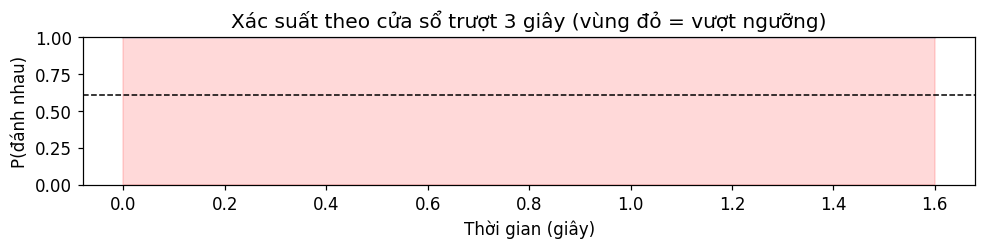

=== no484_xvid.avi | thực tế: BÌNH THƯỜNG (model báo nhầm) | model (cả clip): ĐÁNH NHAU (p=1.00) | 0.3s


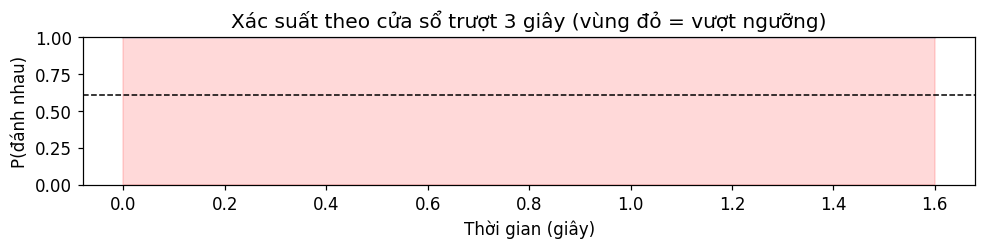

=== no99_xvid.avi | thực tế: BÌNH THƯỜNG (model báo nhầm) | model (cả clip): ĐÁNH NHAU (p=1.00) | 0.2s


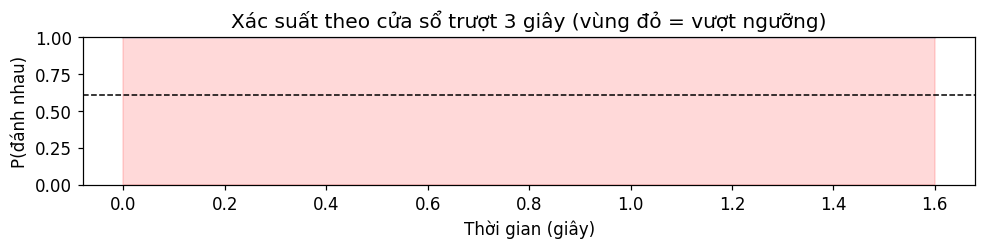

=== fi40_xvid.avi | thực tế: ĐÁNH NHAU (model bỏ sót) | model (cả clip): BÌNH THƯỜNG (p=0.00) | 0.3s


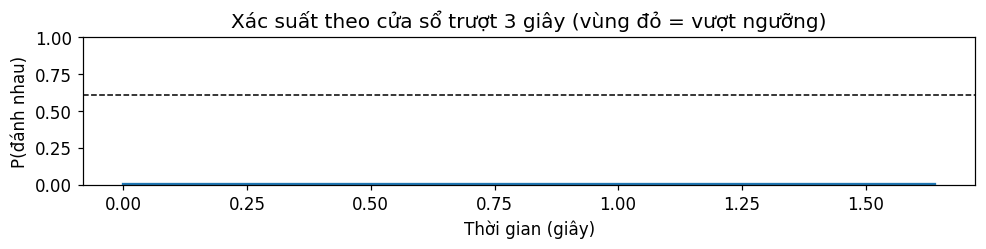

=== fi37_xvid.avi | thực tế: ĐÁNH NHAU (model bỏ sót) | model (cả clip): BÌNH THƯỜNG (p=0.01) | 0.2s


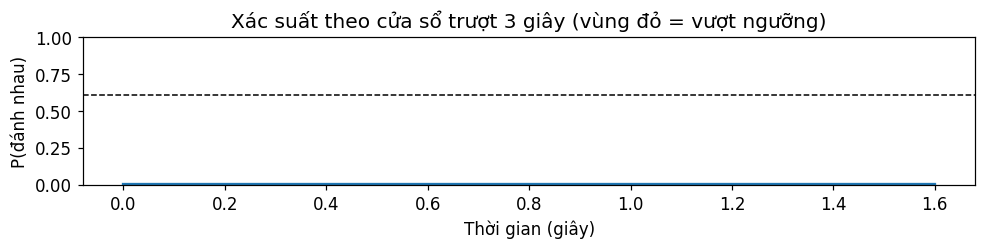

In [10]:
if not (OUT_DIR / 'pred_hockey.csv').exists():
    print('Chưa có pred_hockey.csv')
else:
    hk = pd.read_csv(OUT_DIR / 'pred_hockey.csv')
    fpp = hk[(hk.label == 0) & (hk.pred == 1)].sort_values('prob', ascending=False).head(3)
    fnn = hk[(hk.label == 1) & (hk.pred == 0)].sort_values('prob').head(2)
    for df, exp in [(fpp, 'BÌNH THƯỜNG (model báo nhầm)'), (fnn, 'ĐÁNH NHAU (model bỏ sót)')]:
        for _, r in df.iterrows():
            out = get_clip(r.path)
            if out: demo(out, exp)